# 02 · Experimento de recorte inferior — CCSN

**Objetivo:** eliminar el 20 % inferior de las imágenes **después de `data/processed`**, conservar los mismos splits (`train`, `val`, `test`), recalcular la normalización con **train solamente**, entrenar una CNN con `run_name="recorte_inferior"` y visualizar sus *feature maps*.

No se modifican `src/*.py`, los datos originales ni el checkpoint `baseline_best.pt`. **Ejecuta las celdas en orden**. La celda de entrenamiento tarda y se ejecuta únicamente cuando tú la inicies. No se usa test para seleccionar el modelo.

## 1. Rutas e importaciones

In [14]:
from pathlib import Path
import sys
import json
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision.datasets import ImageFolder

ROOT = Path(r"C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal")
if not (ROOT / "src").is_dir():
    ROOT = Path.cwd().resolve()
    if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
        ROOT = ROOT.parent
assert (ROOT / "src" / "clouds_cnn").is_dir(), f"No se encontró src/clouds_cnn en {ROOT}"
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from clouds_cnn.config import ExperimentConfig
from clouds_cnn.data import (build_base_transform, compute_channel_stats,
                             load_dataset_stats, make_split_loader)
from clouds_cnn.experiment import build_model, run_experiment
from clouds_cnn.inspection import capture_feature_maps

RAW = ROOT / "data" / "raw"
CURATED = ROOT / "data" / "curated"
PROCESSED = ROOT / "data" / "processed"
PROCESSED_RECORTE = ROOT / "data" / "processed_bottom_crop"

print("Proyecto:", ROOT)
print("Origen:", PROCESSED)
print("Destino:", PROCESSED_RECORTE)

Proyecto: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal
Origen: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\data\processed
Destino: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\data\processed_bottom_crop


## 2. Verificar el dataset preparado y configurar el recorte

`PORCENTAJE=0.20` significa **eliminar el 20 % inferior**, no conservarlo. Para evitar mezclar resultados, si cambias el porcentaje elimina primero la carpeta `processed_bottom_crop` o elige otro nombre de destino.

In [2]:
PORCENTAJE = 0.20
EXTENSIONES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLITS = ("train", "val", "test")

assert 0 <= PORCENTAJE < 1
assert (PROCESSED / "dataset_stats.json").is_file()
assert all((PROCESSED / split).is_dir() for split in SPLITS)
assert PROCESSED.resolve() != PROCESSED_RECORTE.resolve()

stats_original = load_dataset_stats(PROCESSED)
print("Clases:", stats_original["class_to_label"])
print("Transformación original:", stats_original["transform"])
print("Porcentaje eliminado:", PORCENTAJE * 100, "%")

Clases: {'Ac': 0, 'As': 1, 'Cb': 2, 'Cc': 3, 'Ci': 4, 'Cs': 5, 'Ct': 6, 'Cu': 7, 'Ns': 8, 'Sc': 9, 'St': 10}
Transformación original: {'image_size': 256, 'center_crop': None, 'ops': ['Resize', 'ToTensor']}
Porcentaje eliminado: 20.0 %


## 3. Crear las imágenes recortadas (sin modificar `processed`)

Se conserva el nombre y la ubicación de cada archivo. No se vuelve a realizar el split. La celda no sobrescribe silenciosamente un conjunto ya generado.

In [3]:
if PROCESSED_RECORTE.exists() and any(PROCESSED_RECORTE.iterdir()):
    print("El destino ya contiene archivos; se conserva sin volver a recortar:", PROCESSED_RECORTE)
else:
    total = 0
    for split in SPLITS:
        archivos = [p for p in (PROCESSED / split).rglob("*")
                    if p.is_file() and p.suffix.lower() in EXTENSIONES]
        assert archivos, f"No hay imágenes en {split}"
        for archivo in archivos:
            salida = PROCESSED_RECORTE / archivo.relative_to(PROCESSED)
            salida.parent.mkdir(parents=True, exist_ok=True)
            with Image.open(archivo) as img:
                ancho, alto = img.size
                altura = max(1, round(alto * (1 - PORCENTAJE)))
                recortada = img.crop((0, 0, ancho, altura))
                recortada.save(salida)
        total += len(archivos)
        print(f"{split}: {len(archivos)} imágenes recortadas")
    shutil.copy2(PROCESSED / "dataset_stats.json", PROCESSED_RECORTE / "dataset_stats.json")
    if (PROCESSED / "manifest.csv").is_file():
        shutil.copy2(PROCESSED / "manifest.csv", PROCESSED_RECORTE / "manifest.csv")
    print("Total:", total)

train: 1766 imágenes recortadas
val: 378 imágenes recortadas
test: 379 imágenes recortadas
Total: 2523


## 4. Verificación visual y conteo por partición

train: 1766 originales / 1766 recortadas
val: 378 originales / 378 recortadas
test: 379 originales / 379 recortadas


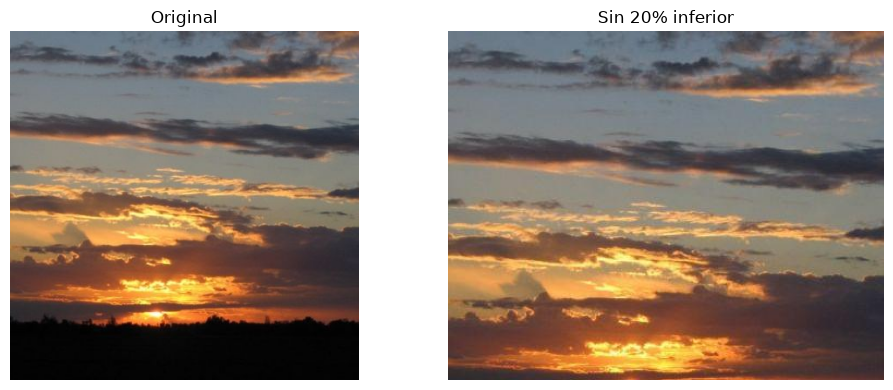

In [4]:
for split in SPLITS:
    original = ImageFolder(PROCESSED / split)
    recortado = ImageFolder(PROCESSED_RECORTE / split)
    assert original.classes == recortado.classes
    assert len(original) == len(recortado)
    print(f"{split}: {len(original)} originales / {len(recortado)} recortadas")

archivo = next(p for p in (PROCESSED / "val").rglob("*")
               if p.is_file() and p.suffix.lower() in EXTENSIONES)
with Image.open(archivo) as img:
    original_img = img.convert("RGB").copy()
with Image.open(PROCESSED_RECORTE / archivo.relative_to(PROCESSED)) as img:
    recortada_img = img.convert("RGB").copy()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(original_img)
axes[0].set_title("Original")
axes[1].imshow(recortada_img)
axes[1].set_title(f"Sin {PORCENTAJE:.0%} inferior")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Recalcular media y desviación estándar (solo train)

`clouds_cnn.data` requiere las claves `mean_train` y `std_train` calculadas **después del Resize a 256×256**. Se conservan las demás claves de `dataset_stats.json`, incluido el split y las etiquetas. `center_crop` debe coincidir con el utilizado durante la preparación.

In [5]:
stats_recorte = load_dataset_stats(PROCESSED_RECORTE)
transform_info = stats_recorte["transform"]
transformacion = build_base_transform(
    image_size=transform_info["image_size"],
    center_crop=transform_info["center_crop"],
)
train_recortado = ImageFolder(PROCESSED_RECORTE / "train", transform=transformacion)
media, desviacion = compute_channel_stats(train_recortado, batch_size=64, num_workers=0)
assert all(valor > 0 for valor in desviacion)

stats_recorte["mean_train"] = media
stats_recorte["std_train"] = desviacion
stats_recorte["bottom_crop_fraction"] = PORCENTAJE
with (PROCESSED_RECORTE / "dataset_stats.json").open("w", encoding="utf-8") as f:
    json.dump(stats_recorte, f, indent=2, ensure_ascii=False)

print("Media train:", media)
print("Desviación train:", desviacion)
print("Estadísticas guardadas en:", PROCESSED_RECORTE / "dataset_stats.json")

Media train: [0.5109049796918628, 0.5590024348340602, 0.6083563914002763]
Desviación train: [0.25134957898827676, 0.21494732017228838, 0.22230187266072832]
Estadísticas guardadas en: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\data\processed_bottom_crop\dataset_stats.json


## 6. Configuración del experimento

Se utilizan los hiperparámetros solicitados: **15 épocas, batch size 64, BatchNorm y 0 workers**. Se asigna un nombre de run diferente para no sobrescribir `baseline_best.pt`.

In [6]:
config_recorte = ExperimentConfig(
    run_name="recorte_inferior",
    data_root=PROCESSED_RECORTE,
    output_root=ROOT / "outputs",
    num_workers=0,
    epochs=15,
    batch_size=64,
    use_batchnorm=True,
    center_crop=stats_recorte["transform"]["center_crop"],
    image_size=stats_recorte["transform"]["image_size"],
    split_seed=stats_recorte["split_seed"],
)
assert config_recorte.num_classes == 11 and config_recorte.image_size == 256
assert len(stats_recorte["class_to_label"]) == config_recorte.num_classes
assert (config_recorte.data_root / "dataset_stats.json").is_file()
assert config_recorte.run_name != "baseline"
print(config_recorte)
print("Checkpoint esperado:", config_recorte.output_root / "checkpoints" / "recorte_inferior_best.pt")

ExperimentConfig(run_name='recorte_inferior', split_seed=2026, train_seed=2026, deterministic=False, num_classes=11, image_size=256, center_crop=None, batch_size=64, num_workers=0, use_batchnorm=True, dropout_p=0.0, learning_rate=0.001, weight_decay=0.0, epochs=15, device_preference='auto', data_root=WindowsPath('C:/Users/Dany/Documents/Codigo de Matematicas cualquiera/Sistemas Inteligentes II/CNN-Nubes-Corte-II_FInal/data/processed_bottom_crop'), output_root=WindowsPath('C:/Users/Dany/Documents/Codigo de Matematicas cualquiera/Sistemas Inteligentes II/CNN-Nubes-Corte-II_FInal/outputs'), mlflow_experiment_name='clouds-cnn-from-scratch')
Checkpoint esperado: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\checkpoints\recorte_inferior_best.pt


## 7. Entrenar el modelo recortado (train + validation)

**Ejecuta esta celda una sola vez cuando quieras iniciar el entrenamiento.** `run_experiment` selecciona el mejor checkpoint según `val_loss` y no utiliza test.

In [7]:
resultado_recorte = run_experiment(config_recorte)
print("Checkpoint:", resultado_recorte.checkpoint_path)
print("Métricas finales:", resultado_recorte.final_metrics())

Época   1/15 | train loss 2.1750 acc 0.2163 | val loss 2.1530 acc 0.2513 | 189.5s *
Época   2/15 | train loss 1.9985 acc 0.2973 | val loss 1.9610 acc 0.3228 | 194.2s *
Época   3/15 | train loss 1.9402 acc 0.3324 | val loss 1.9097 acc 0.3042 | 168.3s *
Época   4/15 | train loss 1.8618 acc 0.3516 | val loss 1.8981 acc 0.3254 | 168.2s *
Época   5/15 | train loss 1.8055 acc 0.3675 | val loss 1.8626 acc 0.3439 | 168.7s *
Época   6/15 | train loss 1.7871 acc 0.3743 | val loss 1.9007 acc 0.3360 | 172.6s
Época   7/15 | train loss 1.7412 acc 0.3834 | val loss 1.8706 acc 0.3413 | 178.6s
Época   8/15 | train loss 1.7085 acc 0.4043 | val loss 1.8484 acc 0.3651 | 173.6s *
Época   9/15 | train loss 1.6781 acc 0.4094 | val loss 1.8742 acc 0.3307 | 174.8s
Época  10/15 | train loss 1.6389 acc 0.4287 | val loss 1.8483 acc 0.3571 | 173.5s *
Época  11/15 | train loss 1.6035 acc 0.4326 | val loss 1.8396 acc 0.3677 | 174.3s *
Época  12/15 | train loss 1.5832 acc 0.4536 | val loss 1.8186 acc 0.3836 | 177.4s 

## 8. Recuperar el checkpoint y observar feature maps

No se reentrena. Se utiliza el constructor **real** `clouds_cnn.experiment.build_model`, y la utilidad existente `capture_feature_maps` de `clouds_cnn.inspection`. La inspección usa una imagen de validación.

In [8]:
checkpoint_recorte = config_recorte.output_root / "checkpoints" / "recorte_inferior_best.pt"
assert checkpoint_recorte.is_file(), "Entrena primero el experimento de recorte inferior."

device = torch.device("cpu")
modelo_recorte = build_model(config_recorte).to(device)
checkpoint = torch.load(checkpoint_recorte, map_location=device, weights_only=True)
modelo_recorte.load_state_dict(checkpoint["model_state_dict"])
modelo_recorte.eval()

loader_val = make_split_loader(config_recorte, "val")
imagenes, etiquetas = next(iter(loader_val))
imagen = imagenes[:1]
clase_real = loader_val.dataset.classes[int(etiquetas[0])]
with torch.no_grad():
    logits = modelo_recorte(imagen.to(device))
prediccion = loader_val.dataset.classes[int(logits.argmax(dim=1).item())]
print("Clase real:", clase_real, "| Predicción:", prediccion)

capas = [nombre for nombre, modulo in modelo_recorte.named_modules()
         if nombre.endswith(".act") and isinstance(modulo, torch.nn.ReLU)]
assert capas, "No se encontraron capas de activación .act en la arquitectura."
print("Capas:", capas)

Clase real: Ac | Predicción: Ac
Capas: ['features.block1.act', 'features.block2.act', 'features.block3.act', 'features.block4.act', 'classifier.act']


## 9. Dibujar y guardar hasta 16 mapas por capa

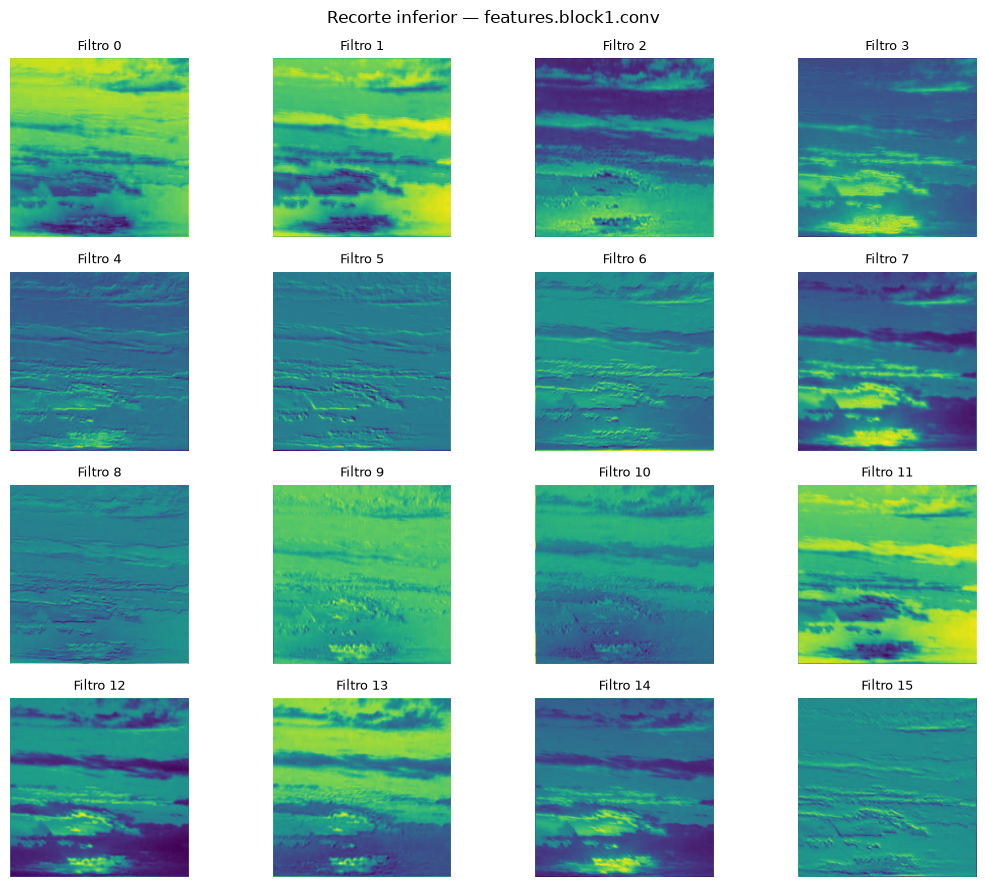

Guardado: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\feature_maps\recorte_inferior\features_block1_conv.png


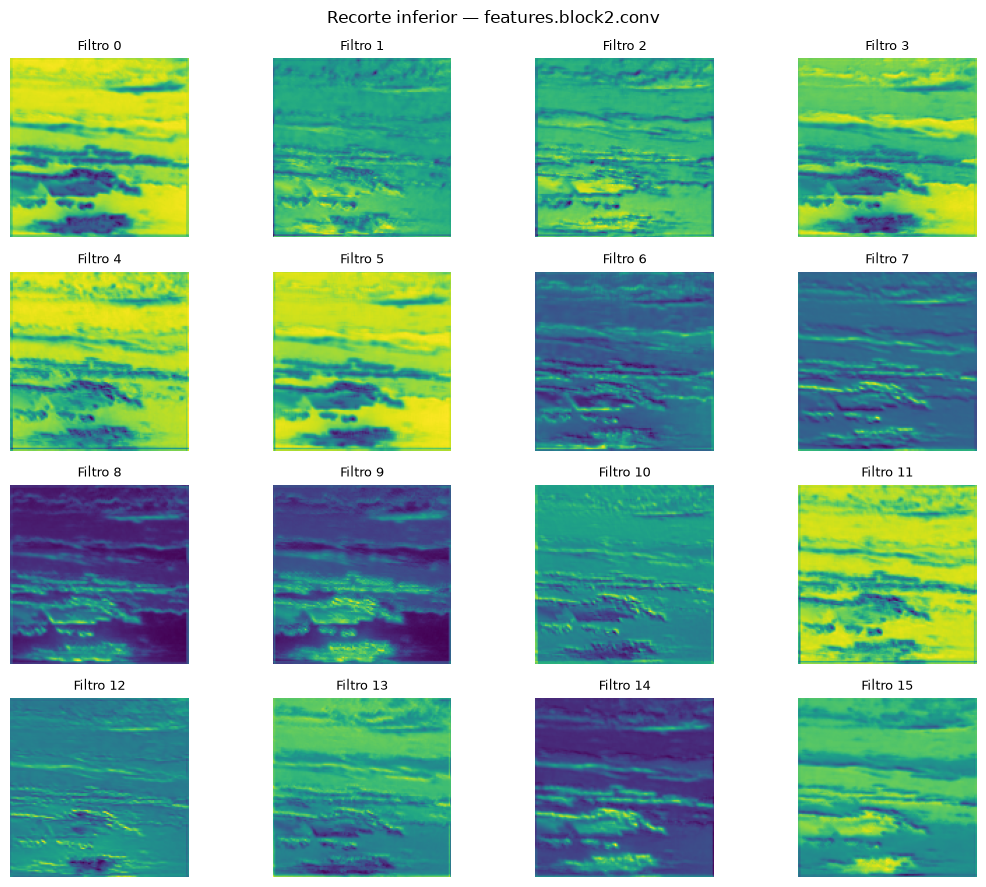

Guardado: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\feature_maps\recorte_inferior\features_block2_conv.png


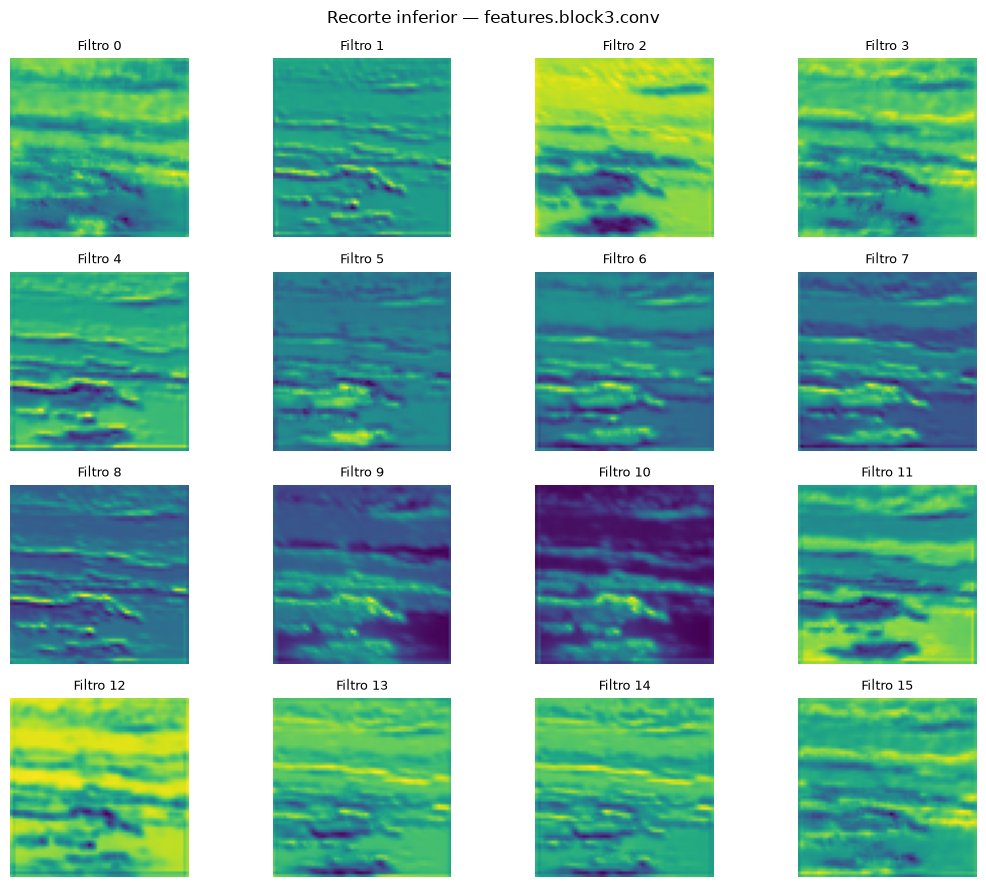

Guardado: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\feature_maps\recorte_inferior\features_block3_conv.png


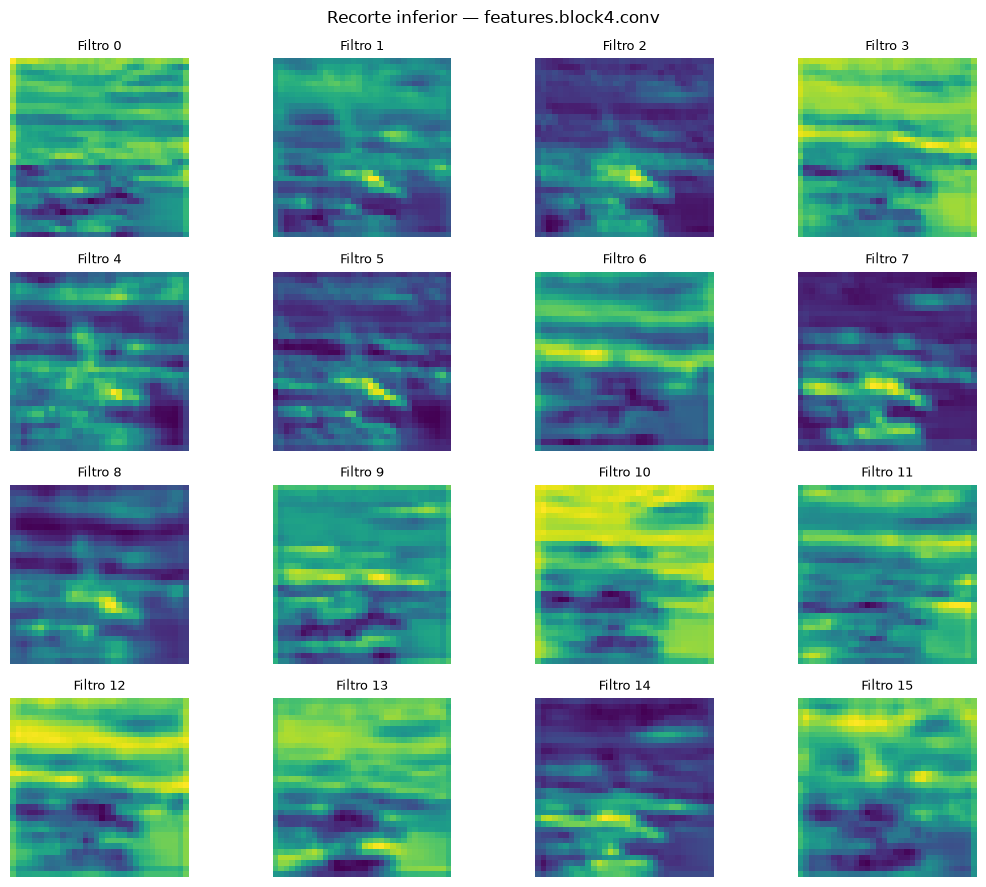

Guardado: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\feature_maps\recorte_inferior\features_block4_conv.png

Mapas guardados: 4
Directorio: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\feature_maps\recorte_inferior


In [11]:
from pathlib import Path
from torch import nn

# Directorio donde se guardarán los mapas de características.
salida_mapas = (
    config_recorte.output_root
    / "feature_maps"
    / "recorte_inferior"
)
salida_mapas.mkdir(parents=True, exist_ok=True)

# Identificar las capas convolucionales del modelo.
capas_convolucionales = [
    nombre
    for nombre, modulo in modelo_recorte.named_modules()
    if nombre and isinstance(modulo, nn.Conv2d)
]

if not capas_convolucionales:
    raise ValueError(
        "No se encontraron capas Conv2d en modelo_recorte."
    )

# Evaluar y capturar los mapas de cada capa convolucional.
modelo_recorte.eval()
mapas_guardados = 0
capas_fallidas = []

for nombre in capas_convolucionales:
    try:
        with torch.no_grad():
            salida = capture_feature_maps(
                modelo_recorte,
                imagen,
                nombre,
                device,
            )

        mapas = salida[0]

        # Verificar la forma esperada: (C, H, W) después de
        # seleccionar la primera imagen del lote.
        if mapas.ndim != 3:
            raise ValueError(
                f"Se esperaba un tensor (C, H, W), "
                f"pero se obtuvo {tuple(mapas.shape)}."
            )

        # Pasar los mapas a CPU antes de convertirlos a NumPy.
        mapas = mapas.detach().cpu()

        fig, axes = plt.subplots(
            4, 4, figsize=(11, 9)
        )

        for i, ax in enumerate(axes.flat):
            ax.axis("off")

            if i < min(16, mapas.shape[0]):
                ax.imshow(
                    mapas[i].numpy(),
                    cmap="viridis",
                )
                ax.set_title(
                    f"Filtro {i}",
                    fontsize=9,
                )

        fig.suptitle(
            f"Recorte inferior — {nombre}",
            fontsize=12,
        )
        fig.tight_layout()

        # Crear un nombre de archivo válido a partir del módulo.
        nombre_archivo = (
            nombre.replace(".", "_").replace("/", "_")
        )
        archivo = salida_mapas / f"{nombre_archivo}.png"

        fig.savefig(
            archivo,
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        mapas_guardados += 1

        print(f"Guardado: {archivo}")

        plt.close(fig)

    except (ValueError, RuntimeError, IndexError) as error:
        capas_fallidas.append((nombre, str(error)))
        print(f"Se omite la capa {nombre!r}: {error}")

print(f"\nMapas guardados: {mapas_guardados}")
print("Directorio:", salida_mapas)

if capas_fallidas:
    print("\nCapas que no pudieron procesarse:")
    for nombre, error in capas_fallidas:
        print(f"  - {nombre}: {error}")


MÉTRICAS GENERALES


,particion,loss,accuracy,accuracy_%,macro_f1
0,train,1.4502,49.89%,49.89,48.02%
1,val,1.8034,36.77%,36.77,33.68%



MÉTRICAS POR CLASE — TRAIN


,clase,muestras,aciertos,accuracy_clase,precision,recall,f1
0,Ac,153,56,36.60%,43.75%,36.60%,39.86%
1,As,130,40,30.77%,55.56%,30.77%,39.60%
2,Cb,165,119,72.12%,49.58%,72.12%,58.77%
3,Cc,186,119,63.98%,51.29%,63.98%,56.94%
4,Ci,97,44,45.36%,44.44%,45.36%,44.90%
5,Cs,200,66,33.00%,44.00%,33.00%,37.71%
6,Ct,140,107,76.43%,76.98%,76.43%,76.70%
7,Cu,124,55,44.35%,56.12%,44.35%,49.55%
8,Ns,192,88,45.83%,42.72%,45.83%,44.22%
9,Sc,238,163,68.49%,48.95%,68.49%,57.09%


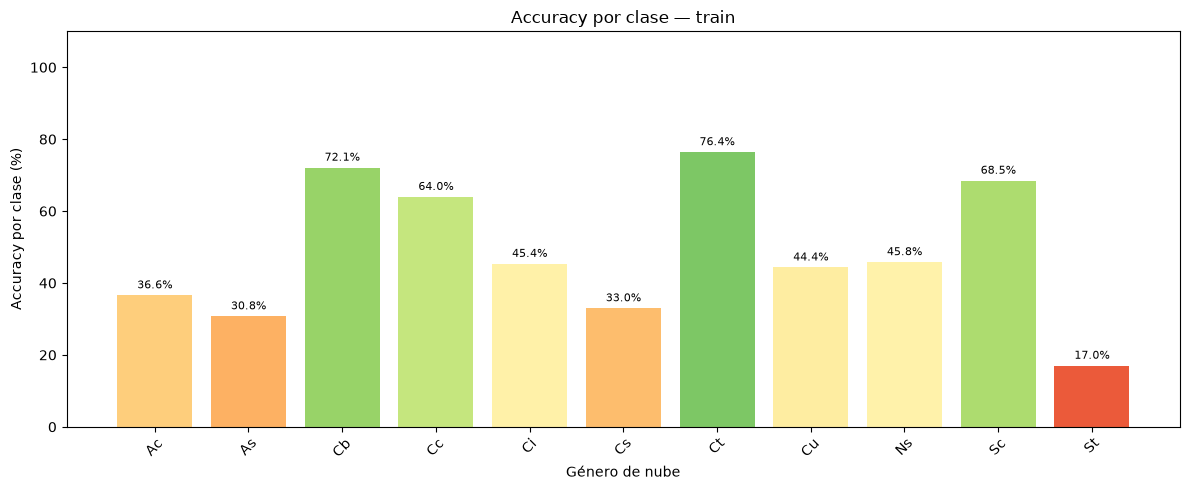

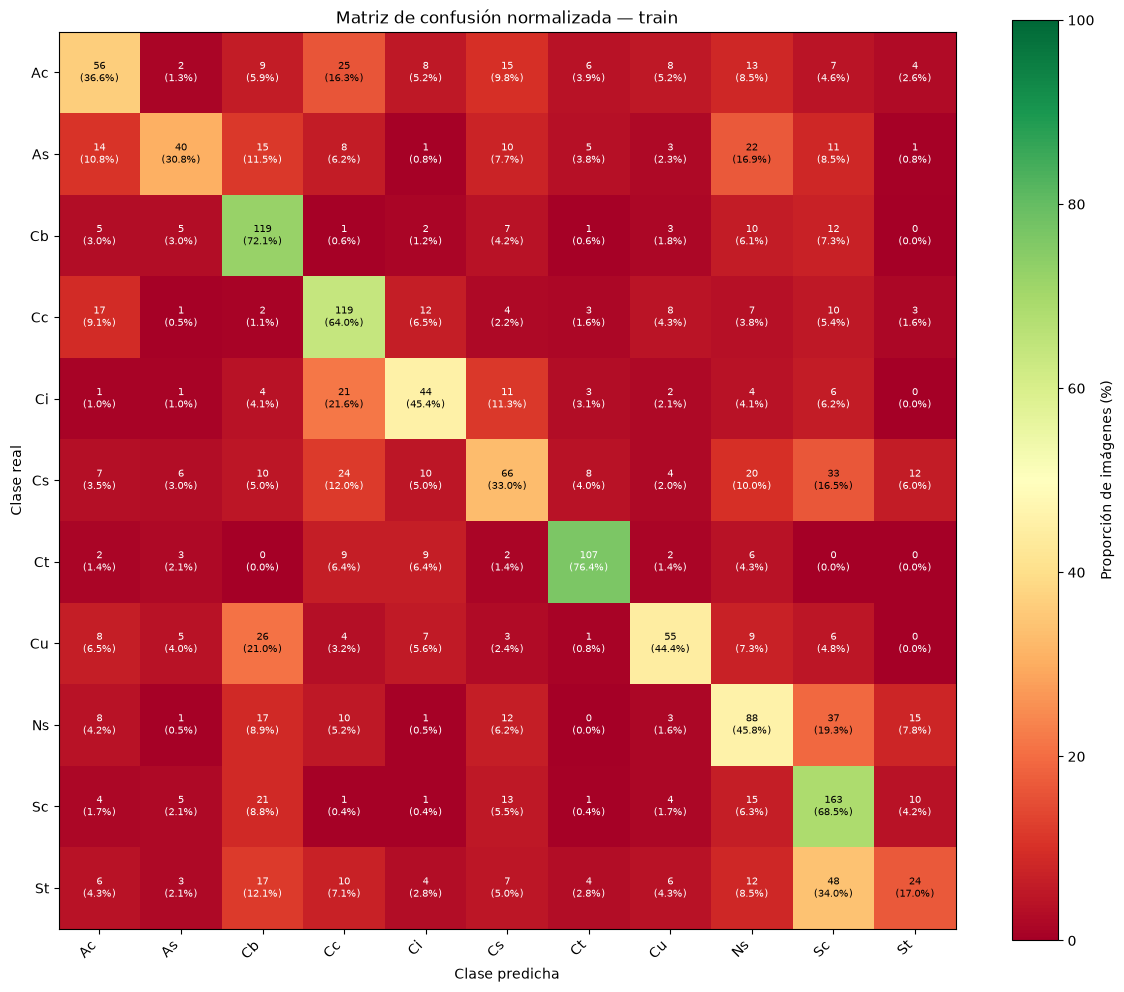


MÉTRICAS POR CLASE — VAL


,clase,muestras,aciertos,accuracy_clase,precision,recall,f1
0,Ac,33,7,21.21%,29.17%,21.21%,24.56%
1,As,28,6,21.43%,54.55%,21.43%,30.77%
2,Cb,35,20,57.14%,32.79%,57.14%,41.67%
3,Cc,39,20,51.28%,43.48%,51.28%,47.06%
4,Ci,21,1,4.76%,5.00%,4.76%,4.88%
5,Cs,43,11,25.58%,25.58%,25.58%,25.58%
6,Ct,30,19,63.33%,67.86%,63.33%,65.52%
7,Cu,27,7,25.93%,38.89%,25.93%,31.11%
8,Ns,41,15,36.59%,38.46%,36.59%,37.50%
9,Sc,51,30,58.82%,41.67%,58.82%,48.78%


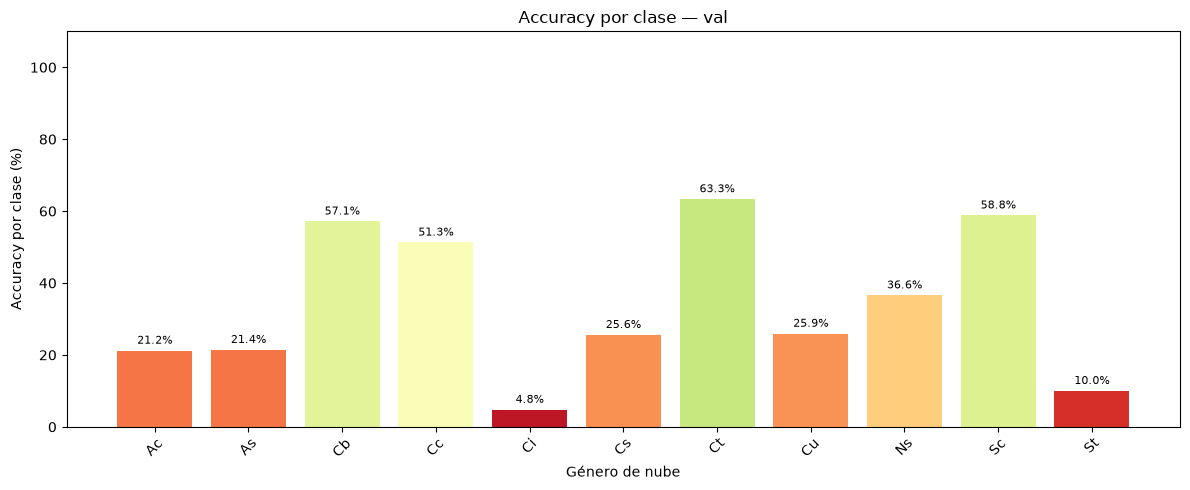

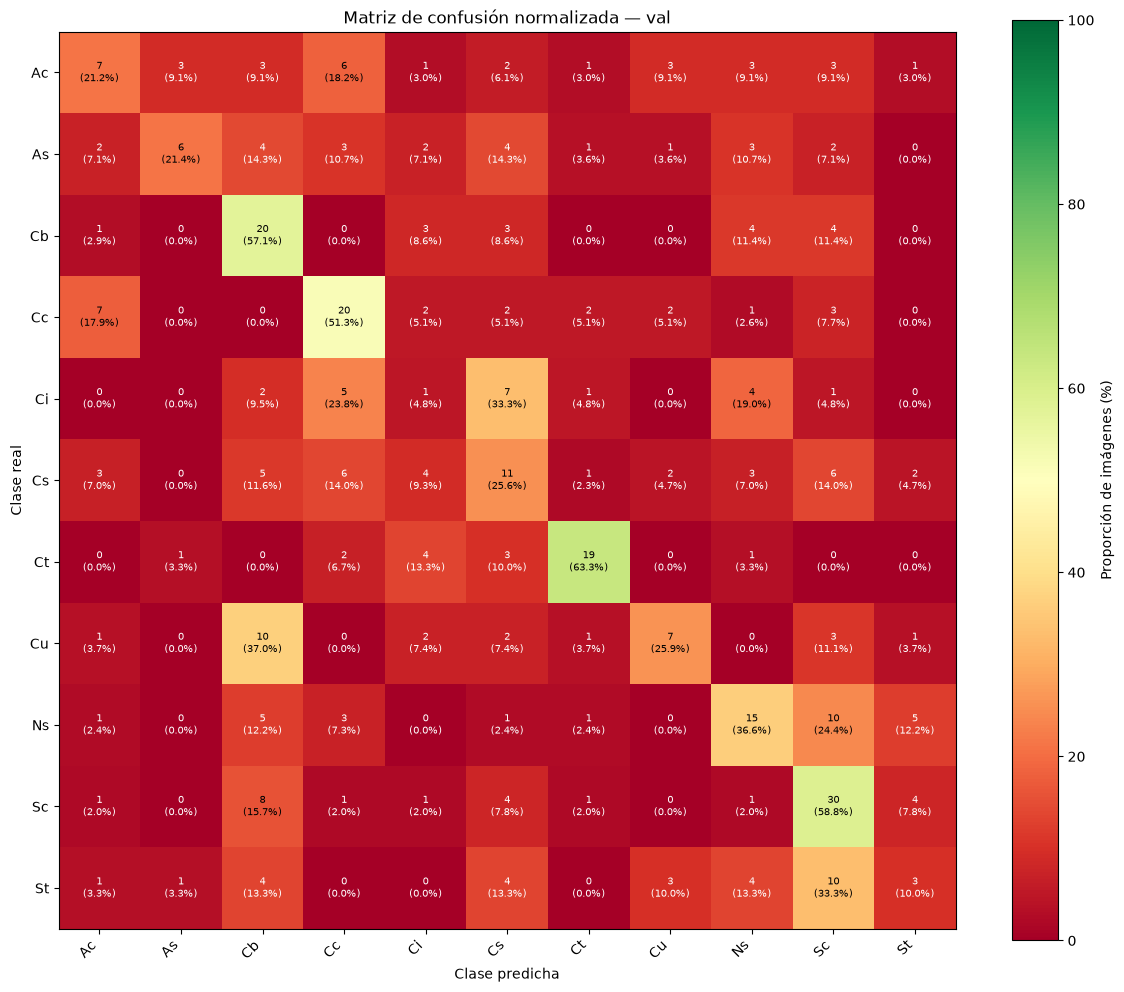


HISTORIAL DE ENTRENAMIENTO


,train_loss,train_acc,val_loss,val_acc,lr,epoch_time,best_epoch,best_val_loss
0,2.1750,0.2163,2.1530,0.2513,0.001,189.4660,14,1.8034
1,1.9985,0.2973,1.9610,0.3228,0.001,194.1586,14,1.8034
2,1.9402,0.3324,1.9097,0.3042,0.001,168.2846,14,1.8034
3,1.8618,0.3516,1.8981,0.3254,0.001,168.2097,14,1.8034
4,1.8055,0.3675,1.8626,0.3439,0.001,168.6887,14,1.8034
5,1.7871,0.3743,1.9007,0.3360,0.001,172.5599,14,1.8034
6,1.7412,0.3834,1.8706,0.3413,0.001,178.6278,14,1.8034
7,1.7085,0.4043,1.8484,0.3651,0.001,173.5959,14,1.8034
8,1.6781,0.4094,1.8742,0.3307,0.001,174.7631,14,1.8034
9,1.6389,0.4287,1.8483,0.3571,0.001,173.5268,14,1.8034


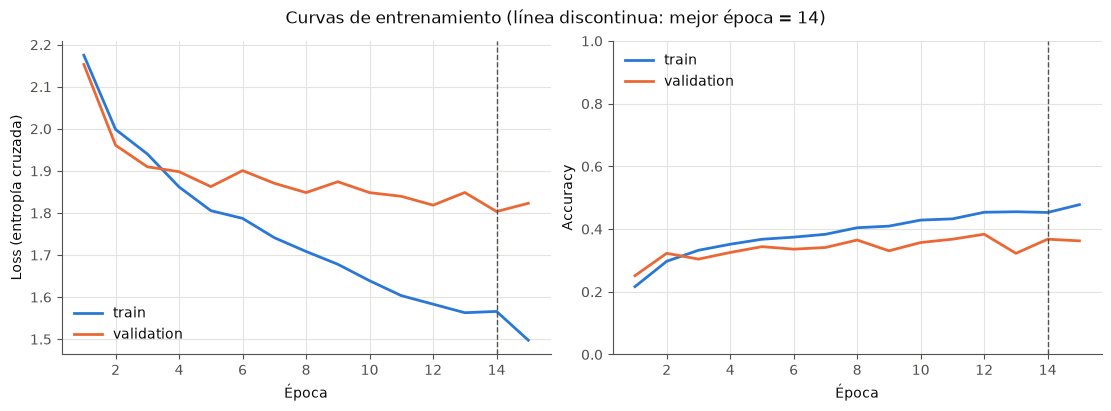


RESUMEN DEL EXPERIMENTO


,experimento,mejor_epoca,mejor_val_loss,train_accuracy,val_accuracy,generalization_gap
0,recorte_inferior,14,1.8034,0.4989,0.3677,0.1311



Todos los archivos se guardaron en:
C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\metricas\recorte_inferior


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from clouds_cnn.plots import (
    plot_confusion_matrix,
    plot_training_curves,
)

# Seleccionar el experimento entrenado.
resultado = resultado_recorte

# Crear la carpeta de resultados.
SALIDA = (
    Path(resultado.config.output_root)
    / "metricas"
    / resultado.config.run_name
)
SALIDA.mkdir(parents=True, exist_ok=True)

# Obtener las evaluaciones ya calculadas.
clases = list(resultado.class_names)

evaluaciones = {
    "train": resultado.train_eval.to_dict(clases),
    "val": resultado.val_eval.to_dict(clases),
}

# Construir las métricas generales.
filas_generales = []

for particion, evaluacion in evaluaciones.items():
    filas_generales.append({
        "particion": particion,
        "loss": evaluacion["loss"],
        "accuracy": evaluacion["accuracy"],
        "accuracy_%": evaluacion["accuracy"] * 100,
        "macro_f1": evaluacion["macro_f1"],
    })

tabla_general = pd.DataFrame(filas_generales)
tabla_general.to_csv(
    SALIDA / "metricas_generales.csv",
    index=False,
)

print("MÉTRICAS GENERALES")
display(
    tabla_general.style
    .format({
        "loss": "{:.4f}",
        "accuracy": "{:.2%}",
        "accuracy_%": "{:.2f}",
        "macro_f1": "{:.2%}",
    })
    .background_gradient(
        cmap="RdYlGn",
        subset=["accuracy", "macro_f1"],
        vmin=0,
        vmax=1,
    )
)

# Calcular las métricas por clase.
for particion, evaluacion in evaluaciones.items():

    matriz = np.asarray(
        evaluacion["confusion_matrix"],
        dtype=int,
    )

    assert matriz.shape == (len(clases), len(clases))

    soporte = matriz.sum(axis=1)
    aciertos = np.diag(matriz)

    accuracy_clase = np.divide(
        aciertos,
        soporte,
        out=np.zeros(len(clases), dtype=float),
        where=soporte != 0,
    )

    filas_clases = []

    for i, clase in enumerate(clases):
        valores = evaluacion["per_class"][clase]

        filas_clases.append({
            "clase": clase,
            "muestras": int(soporte[i]),
            "aciertos": int(aciertos[i]),
            "accuracy_clase": float(accuracy_clase[i]),
            "precision": valores["precision"],
            "recall": valores["recall"],
            "f1": valores["f1"],
        })

    tabla_clases = pd.DataFrame(filas_clases)

    # Guardar la tabla por clase.
    tabla_clases.to_csv(
        SALIDA / f"metricas_por_clase_{particion}.csv",
        index=False,
    )

    # 7. Mostrar la tabla coloreada.
    print(f"\nMÉTRICAS POR CLASE — {particion.upper()}")

    display(
        tabla_clases.style
        .format({
            "accuracy_clase": "{:.2%}",
            "precision": "{:.2%}",
            "recall": "{:.2%}",
            "f1": "{:.2%}",
        })
        .background_gradient(
            cmap="RdYlGn",
            subset=[
                "accuracy_clase",
                "precision",
                "recall",
                "f1",
            ],
            vmin=0,
            vmax=1,
        )
    )

    # Graficar el accuracy por clase.
    valores = tabla_clases["accuracy_clase"].to_numpy()
    colores = plt.get_cmap("RdYlGn")(valores)

    fig, ax = plt.subplots(figsize=(12, 5))

    barras = ax.bar(
        tabla_clases["clase"],
        valores * 100,
        color=colores,
    )

    ax.bar_label(
        barras,
        fmt="%.1f%%",
        padding=3,
        fontsize=8,
    )

    ax.set_ylim(0, 110)
    ax.set_ylabel("Accuracy por clase (%)")
    ax.set_xlabel("Género de nube")
    ax.set_title(f"Accuracy por clase — {particion}")
    ax.tick_params(axis="x", rotation=45)

    fig.tight_layout()
    fig.savefig(
        SALIDA / f"accuracy_por_clase_{particion}.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    
    # Matriz de confusión coloreada.

    # Cada fila corresponde a una clase real.
    tabla_matriz = pd.DataFrame(
        matriz,
        index=clases,
        columns=clases,
    )
    tabla_matriz.index.name = "Clase real"

    # Guardar la matriz original con cantidades absolutas.
    tabla_matriz.to_csv(
        SALIDA / f"matriz_confusion_{particion}.csv"
    )

    # Normalizar por filas para obtener proporciones.
    totales = matriz.sum(axis=1, keepdims=True)

    matriz_normalizada = np.divide(
        matriz,
        totales,
        out=np.zeros_like(matriz, dtype=float),
        where=totales != 0,
    )

    # Guardar la matriz normalizada.
    pd.DataFrame(
        matriz_normalizada,
        index=clases,
        columns=clases,
    ).to_csv(
        SALIDA / f"matriz_confusion_normalizada_{particion}.csv"
    )

    # Crear gráfico con escala de colores.
    fig, ax = plt.subplots(figsize=(12, 10))

    imagen = ax.imshow(
        matriz_normalizada,
        cmap="RdYlGn",
        vmin=0,
        vmax=1,
    )

    ax.set_xticks(np.arange(len(clases)))
    ax.set_yticks(np.arange(len(clases)))

    ax.set_xticklabels(clases, rotation=45, ha="right")
    ax.set_yticklabels(clases)

    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(
        f"Matriz de confusión normalizada — {particion}"
    )

    # Mostrar cantidad de imágenes y porcentaje en cada celda.
    for i in range(len(clases)):
        for j in range(len(clases)):
            porcentaje = matriz_normalizada[i, j] * 100

            ax.text(
                j,
                i,
                f"{matriz[i, j]}\n({porcentaje:.1f}%)",
                ha="center",
                va="center",
                fontsize=7,
                color=(
                    "white"
                    if matriz_normalizada[i, j] >= 0.75
                    or matriz_normalizada[i, j] <= 0.15
                    else "black"
                ),
            )

    barra = fig.colorbar(imagen, ax=ax)
    barra.set_label("Proporción de imágenes (%)")
    barra.set_ticks(np.linspace(0, 1, 6))
    barra.set_ticklabels(["0", "20", "40", "60", "80", "100"])

    fig.tight_layout()

    fig.savefig(
        SALIDA / f"matriz_confusion_{particion}.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

# Guardar el historial de entrenamiento.
historial = resultado.history

tabla_historial = pd.DataFrame(historial)
tabla_historial.to_csv(
    SALIDA / "historial_entrenamiento.csv",
    index=False,
)

print("\nHISTORIAL DE ENTRENAMIENTO")
display(tabla_historial.round(4))

# Visualizar las curvas de aprendizaje.
fig = plot_training_curves(historial)

fig.savefig(
    SALIDA / "curvas_entrenamiento.png",
    dpi=150,
    bbox_inches="tight",
)

display(fig)
plt.close(fig)

# Identificar la mejor época.
mejor_epoca = int(
    np.argmin(historial["val_loss"]) + 1
)

mejor_val_loss = float(
    np.min(historial["val_loss"])
)

# Crear el resumen final.
resumen = pd.DataFrame([{
    "experimento": resultado.config.run_name,
    "mejor_epoca": mejor_epoca,
    "mejor_val_loss": mejor_val_loss,
    "train_accuracy": evaluaciones["train"]["accuracy"],
    "val_accuracy": evaluaciones["val"]["accuracy"],
    "generalization_gap": resultado.generalization_gap,
}])

resumen.to_csv(
    SALIDA / "resumen_experimento.csv",
    index=False,
)

print("\nRESUMEN DEL EXPERIMENTO")
display(resumen.round(4))

print("\nTodos los archivos se guardaron en:")
print(SALIDA)


MÉTRICAS POR CLASE — TRAIN


,clase,soporte,aciertos,accuracy_clase,precision,recall,f1,ic_inferior,ic_superior
0,Ac,153,56,36.60%,43.75%,36.60%,39.86%,29.38%,44.48%
1,As,130,40,30.77%,55.56%,30.77%,39.60%,23.48%,39.16%
2,Cb,165,119,72.12%,49.58%,72.12%,58.77%,64.84%,78.40%
3,Cc,186,119,63.98%,51.29%,63.98%,56.94%,56.86%,70.53%
4,Ci,97,44,45.36%,44.44%,45.36%,44.90%,35.82%,55.26%
5,Cs,200,66,33.00%,44.00%,33.00%,37.71%,26.86%,39.78%
6,Ct,140,107,76.43%,76.98%,76.43%,76.70%,68.75%,82.69%
7,Cu,124,55,44.35%,56.12%,44.35%,49.55%,35.91%,53.14%
8,Ns,192,88,45.83%,42.72%,45.83%,44.22%,38.94%,52.89%
9,Sc,238,163,68.49%,48.95%,68.49%,57.09%,62.33%,74.06%


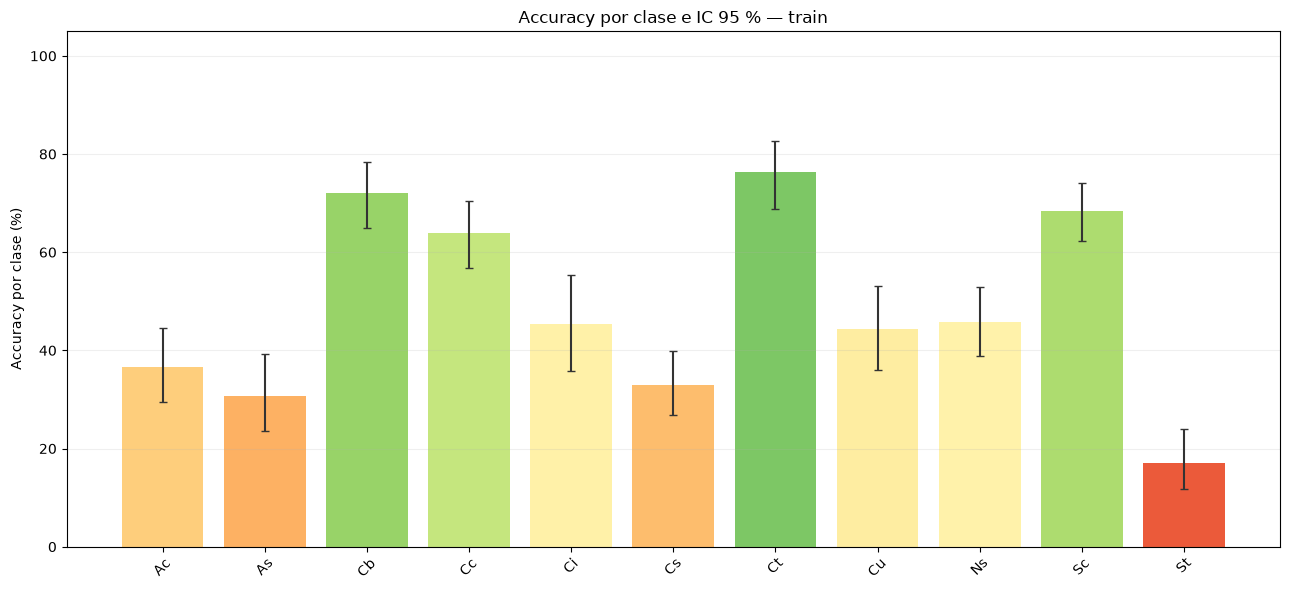

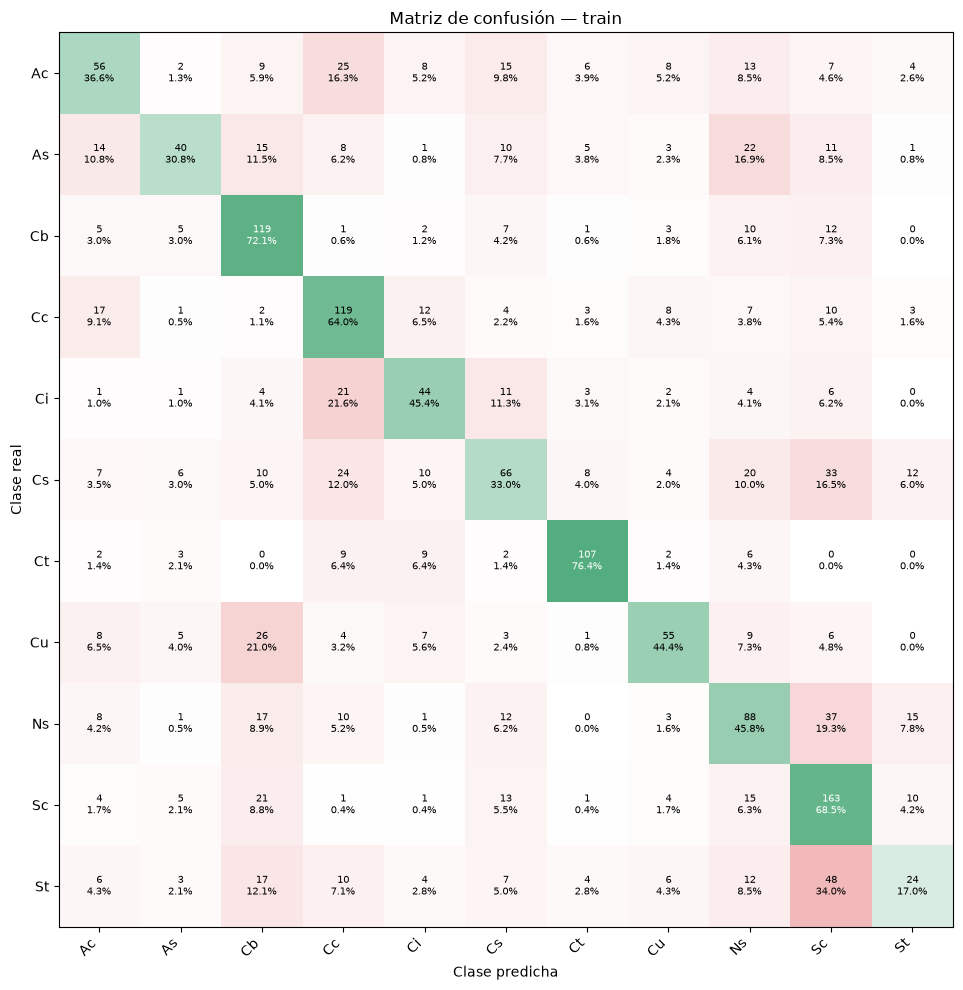


MÉTRICAS POR CLASE — VAL


,clase,soporte,aciertos,accuracy_clase,precision,recall,f1,ic_inferior,ic_superior
0,Ac,33,7,21.21%,29.17%,21.21%,24.56%,10.68%,37.75%
1,As,28,6,21.43%,54.55%,21.43%,30.77%,10.21%,39.54%
2,Cb,35,20,57.14%,32.79%,57.14%,41.67%,40.86%,72.02%
3,Cc,39,20,51.28%,43.48%,51.28%,47.06%,36.20%,66.14%
4,Ci,21,1,4.76%,5.00%,4.76%,4.88%,0.85%,22.67%
5,Cs,43,11,25.58%,25.58%,25.58%,25.58%,14.93%,40.24%
6,Ct,30,19,63.33%,67.86%,63.33%,65.52%,45.51%,78.13%
7,Cu,27,7,25.93%,38.89%,25.93%,31.11%,13.17%,44.68%
8,Ns,41,15,36.59%,38.46%,36.59%,37.50%,23.59%,51.88%
9,Sc,51,30,58.82%,41.67%,58.82%,48.78%,45.17%,71.25%


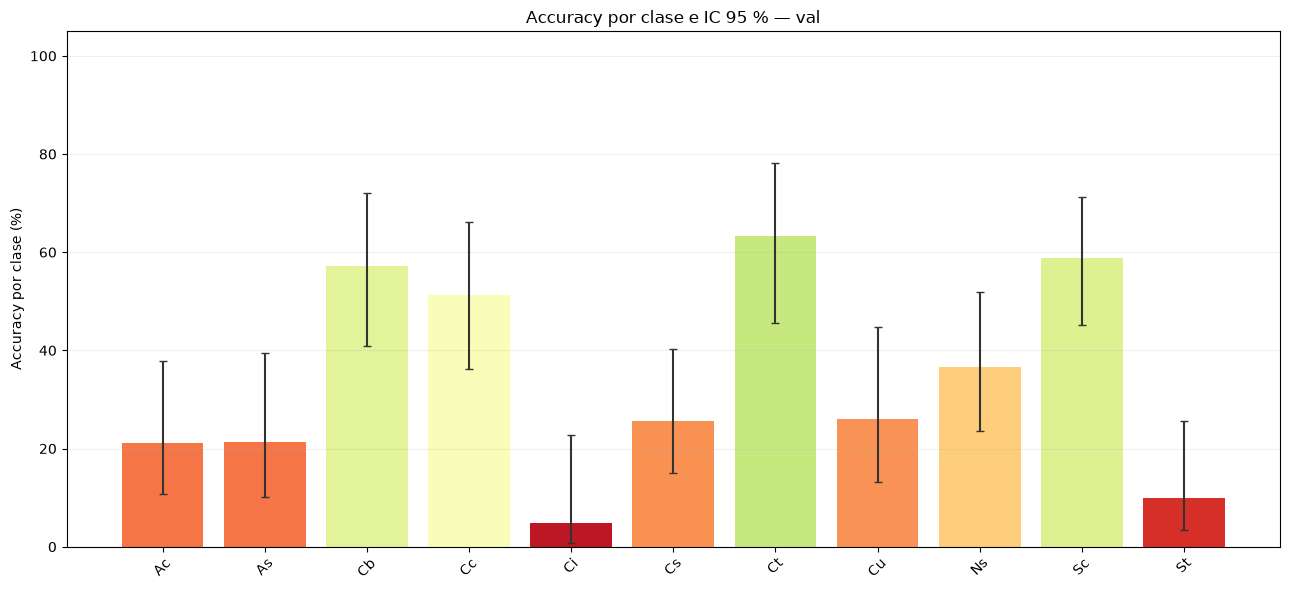

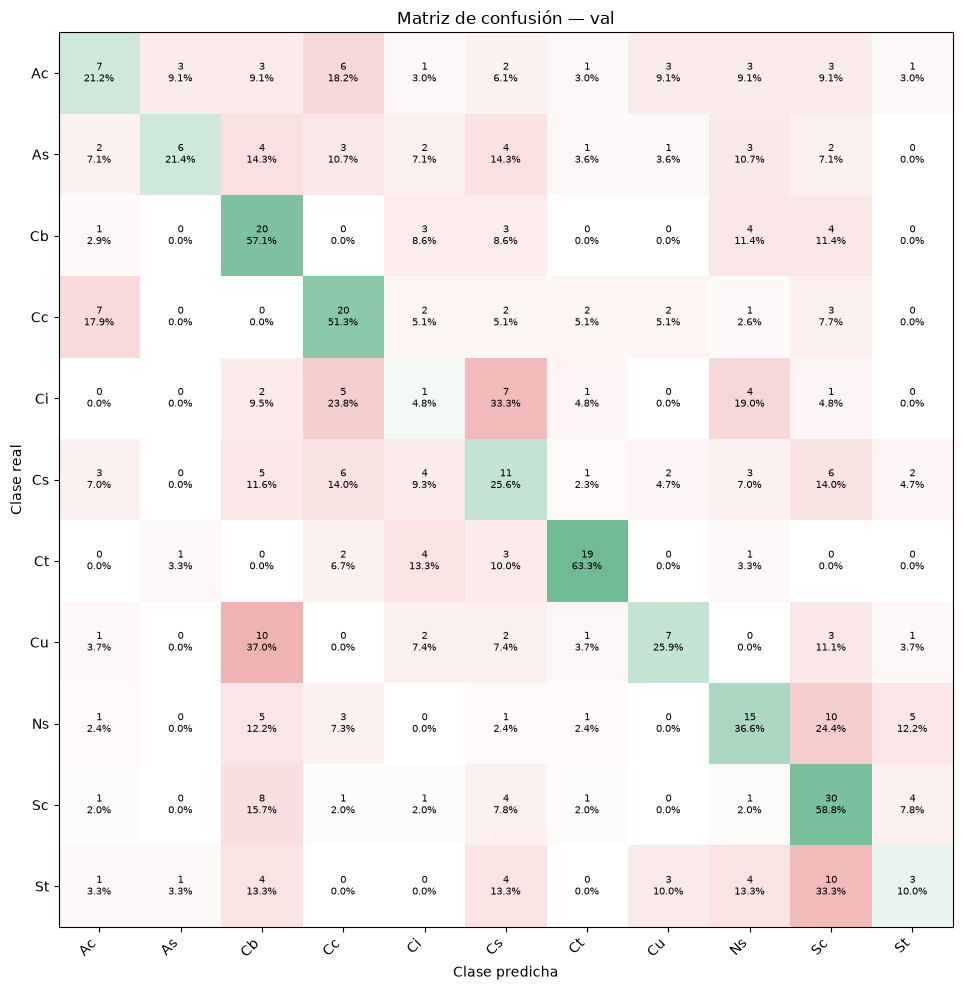


MÉTRICAS GENERALES


,particion,imagenes,aciertos,loss,accuracy,macro_f1,f1_ponderado,ic_inferior,ic_superior
0,train,1766,881,1.4502,49.89%,48.02%,48.48%,47.56%,52.22%
1,val,378,139,1.8034,36.77%,33.68%,35.42%,32.07%,41.74%



MEJOR ÉPOCA: 14
MEJOR VAL LOSS: 1.8034018864707342


,epoca,train_loss,val_loss,train_acc,val_acc
0,1,2.1750,2.1530,21.63%,25.13%
1,2,1.9985,1.9610,29.73%,32.28%
2,3,1.9402,1.9097,33.24%,30.42%
3,4,1.8618,1.8981,35.16%,32.54%
4,5,1.8055,1.8626,36.75%,34.39%
5,6,1.7871,1.9007,37.43%,33.60%
6,7,1.7412,1.8706,38.34%,34.13%
7,8,1.7085,1.8484,40.43%,36.51%
8,9,1.6781,1.8742,40.94%,33.07%
9,10,1.6389,1.8483,42.87%,35.71%


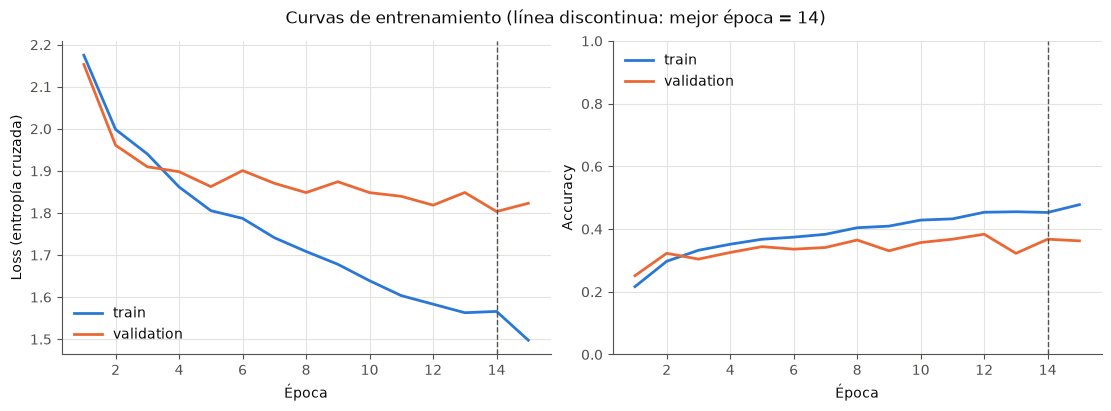

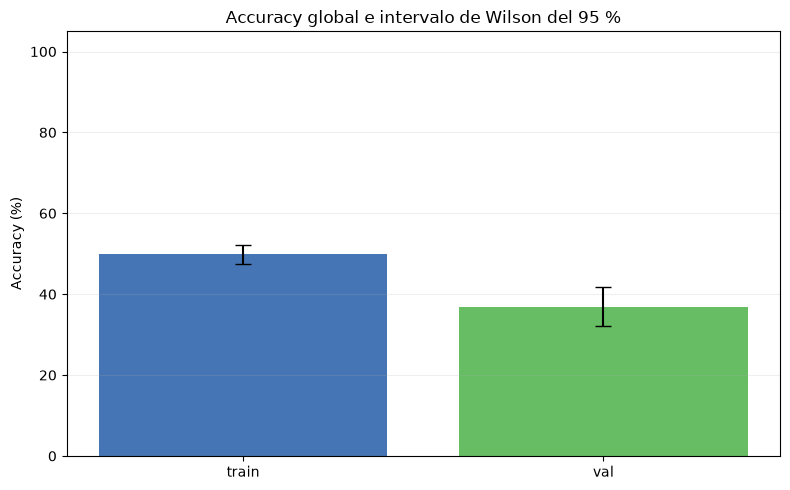


Archivos guardados en: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\metricas\recorte_inferior


In [20]:
import torch
from IPython.display import display

from clouds_cnn.plots import (
    plot_confusion_matrix,
    plot_training_curves,
)

# Resultados de la CNN ya entrenada.
resultado = resultado_recorte
clases = list(resultado.class_names)

SALIDA = (
    Path(resultado.config.output_root)
    / "metricas"
    / resultado.config.run_name
)
SALIDA.mkdir(parents=True, exist_ok=True)

evaluaciones = {
    "train": resultado.train_eval.to_dict(clases),
    "val": resultado.val_eval.to_dict(clases),
}

def intervalo_wilson(aciertos, total, z=1.96):
    """Intervalo de Wilson del 95 % para una proporción."""
    if total == 0:
        return np.nan, np.nan

    p = aciertos / total
    denominador = 1 + z**2 / total
    centro = (p + z**2 / (2 * total)) / denominador
    margen = (
        z
        * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2))
        / denominador
    )
    return centro - margen, centro + margen


def tabla_metricas_clase(evaluacion, nombres):
    """Calcula soporte, métricas e incertidumbre por clase."""
    matriz = np.asarray(evaluacion["confusion_matrix"])
    soporte = matriz.sum(axis=1)
    aciertos = np.diag(matriz)
    filas = []

    for i, clase in enumerate(nombres):
        valores = evaluacion["per_class"][clase]
        inferior, superior = intervalo_wilson(
            int(aciertos[i]),
            int(soporte[i]),
        )
        filas.append({
            "clase": clase,
            "soporte": int(soporte[i]),
            "aciertos": int(aciertos[i]),
            "accuracy_clase": valores["recall"],
            "precision": valores["precision"],
            "recall": valores["recall"],
            "f1": valores["f1"],
            "ic_inferior": inferior,
            "ic_superior": superior,
        })

    return pd.DataFrame(filas)


def grafico_accuracy(tabla, particion, destino):
    """Dibuja accuracy por clase e intervalos de confianza."""
    valores = tabla["accuracy_clase"].to_numpy()
    inferior = tabla["ic_inferior"].to_numpy()
    superior = tabla["ic_superior"].to_numpy()

    errores = np.vstack([
        np.maximum(valores - inferior, 0),
        np.maximum(superior - valores, 0),
    ]) * 100

    fig, ax = plt.subplots(figsize=(13, 6))
    colores = plt.get_cmap("RdYlGn")(valores)

    ax.bar(
        tabla["clase"],
        valores * 100,
        color=colores,
        yerr=errores,
        capsize=3,
        error_kw={"ecolor": "#333333"},
    )

    ax.set_ylim(0, 105)
    ax.set_ylabel("Accuracy por clase (%)")
    ax.set_title(
        f"Accuracy por clase e IC 95 % — {particion}"
    )
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()
    fig.savefig(destino, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def grafico_confusion(matriz, nombres, particion, destino):
    """Muestra porcentajes por fila y aciertos/errores coloreados."""
    totales = matriz.sum(axis=1, keepdims=True)

    normalizada = np.divide(
        matriz,
        totales,
        out=np.zeros_like(matriz, dtype=float),
        where=totales != 0,
    )

    # Verde en la diagonal; rojo fuera de ella.
    colores = np.zeros((*matriz.shape, 3))
    colores[:] = [1.0, 1.0, 1.0]

    for i in range(len(nombres)):
        for j in range(len(nombres)):
            p = normalizada[i, j]
            base = (
                np.array([0.12, 0.58, 0.34])
                if i == j
                else np.array([0.85, 0.20, 0.20])
            )
            colores[i, j] = (1 - p) + p * base

    fig, ax = plt.subplots(figsize=(13, 10))
    ax.imshow(colores, vmin=0, vmax=1)

    ax.set_xticks(range(len(nombres)), nombres)
    ax.set_yticks(range(len(nombres)), nombres)
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")

    for i in range(len(nombres)):
        for j in range(len(nombres)):
            p = normalizada[i, j]
            ax.text(
                j, i,
                f"{matriz[i, j]}\n{p:.1%}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if p >= 0.65 else "black",
            )

    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"Matriz de confusión — {particion}")

    fig.tight_layout()
    fig.savefig(destino, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    return normalizada


# Calcular métricas globales y por clase.
filas_generales = []

for particion, evaluacion in evaluaciones.items():
    tabla = tabla_metricas_clase(evaluacion, clases)
    matriz = np.asarray(
        evaluacion["confusion_matrix"],
        dtype=int,
    )

    soporte = tabla["soporte"].to_numpy()
    f1 = tabla["f1"].to_numpy()
    total = int(soporte.sum())
    aciertos = int(np.trace(matriz))

    f1_ponderado = (
        np.average(f1, weights=soporte)
        if total > 0 else np.nan
    )

    ic_global = intervalo_wilson(aciertos, total)

    filas_generales.append({
        "particion": particion,
        "imagenes": total,
        "aciertos": aciertos,
        "loss": evaluacion["loss"],
        "accuracy": evaluacion["accuracy"],
        "macro_f1": evaluacion["macro_f1"],
        "f1_ponderado": f1_ponderado,
        "ic_inferior": ic_global[0],
        "ic_superior": ic_global[1],
    })

    # Guardar métricas por clase.
    tabla.to_csv(
        SALIDA / f"metricas_por_clase_{particion}.csv",
        index=False,
    )

    print(f"\nMÉTRICAS POR CLASE — {particion.upper()}")

    display(
        tabla.style
        .format({
            "accuracy_clase": "{:.2%}",
            "precision": "{:.2%}",
            "recall": "{:.2%}",
            "f1": "{:.2%}",
            "ic_inferior": "{:.2%}",
            "ic_superior": "{:.2%}",
        })
        .background_gradient(
            cmap="RdYlGn",
            subset=[
                "accuracy_clase",
                "precision",
                "recall",
                "f1",
            ],
            vmin=0,
            vmax=1,
        )
        .background_gradient(
            cmap="Blues",
            subset=["soporte"],
        )
    )

    # Accuracy por clase con incertidumbre.
    grafico_accuracy(
        tabla,
        particion,
        SALIDA / f"accuracy_por_clase_{particion}.png",
    )

    # Guardar matriz de confusión absoluta.
    pd.DataFrame(
        matriz,
        index=clases,
        columns=clases,
    ).to_csv(
        SALIDA / f"matriz_confusion_{particion}.csv"
    )

    # Matriz de confusión coloreada.
    normalizada = grafico_confusion(
        matriz,
        clases,
        particion,
        SALIDA / f"matriz_confusion_{particion}.png",
    )

    # Guardar porcentajes de la matriz.
    pd.DataFrame(
        normalizada,
        index=clases,
        columns=clases,
    ).to_csv(
        SALIDA / f"matriz_normalizada_{particion}.csv"
    )

# Resumen general.
tabla_general = pd.DataFrame(filas_generales)

tabla_general.to_csv(
    SALIDA / "metricas_generales.csv",
    index=False,
)

print("\nMÉTRICAS GENERALES")
display(
    tabla_general.style
    .format({
        "loss": "{:.4f}",
        "accuracy": "{:.2%}",
        "macro_f1": "{:.2%}",
        "f1_ponderado": "{:.2%}",
        "ic_inferior": "{:.2%}",
        "ic_superior": "{:.2%}",
    })
    .background_gradient(
        cmap="RdYlGn",
        subset=["accuracy", "macro_f1", "f1_ponderado"],
        vmin=0,
        vmax=1,
    )
)

# Historial por época.
historial = resultado.history

tabla_historial = pd.DataFrame({
    "epoca": np.arange(1, len(historial["train_loss"]) + 1),
    "train_loss": historial["train_loss"],
    "val_loss": historial["val_loss"],
    "train_acc": historial["train_acc"],
    "val_acc": historial["val_acc"],
})

tabla_historial.to_csv(
    SALIDA / "historial_entrenamiento.csv",
    index=False,
)

mejor_epoca = int(historial["best_epoch"])
print("\nMEJOR ÉPOCA:", mejor_epoca)
print("MEJOR VAL LOSS:", historial["best_val_loss"])

display(
    tabla_historial.style
    .format({
        "train_loss": "{:.4f}",
        "val_loss": "{:.4f}",
        "train_acc": "{:.2%}",
        "val_acc": "{:.2%}",
    })
    .highlight_max(
        subset=["val_acc"],
        color="#b7e4c7",
    )
    .highlight_min(
        subset=["val_loss"],
        color="#b7e4c7",
    )
)

# Curvas del proyecto.
fig = plot_training_curves(historial)
fig.savefig(
    SALIDA / "curvas_entrenamiento.png",
    dpi=200,
    bbox_inches="tight",
)
display(fig)
plt.close(fig)

# Comparación de accuracy global con incertidumbre.
fig, ax = plt.subplots(figsize=(8, 5))

valores = tabla_general["accuracy"].to_numpy()
lim_inf = tabla_general["ic_inferior"].to_numpy()
lim_sup = tabla_general["ic_superior"].to_numpy()

errores = np.vstack([
    np.maximum(valores - lim_inf, 0),
    np.maximum(lim_sup - valores, 0),
]) * 100

ax.bar(
    tabla_general["particion"],
    valores * 100,
    color=["#4575b4", "#66bd63"],
    yerr=errores,
    capsize=6,
)

ax.set_ylim(0, 105)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy global e intervalo de Wilson del 95 %")
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(
    SALIDA / "comparacion_accuracy.png",
    dpi=200,
)
plt.show()
plt.close(fig)

print("\nArchivos guardados en:", SALIDA)
